PRGM 1 Contrast stretching of a low contrast image, Histogram, and Histogram Equalization

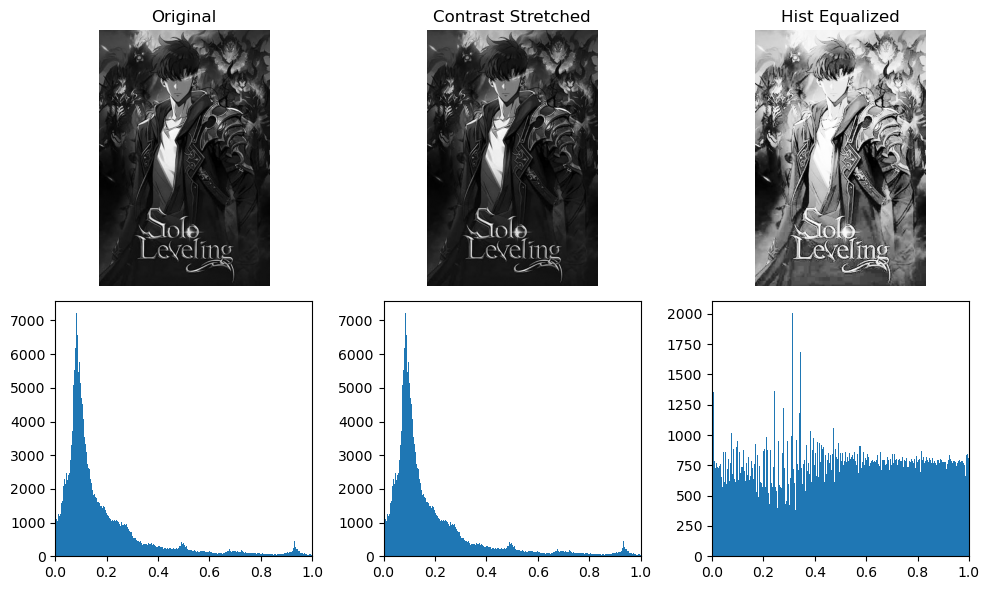

In [2]:
import cv2
import matplotlib.pyplot as plt
from skimage import io, exposure, color

# Read image
img = color.rgb2gray(io.imread(r"C:\Users\GAGAN RAO K\Downloads\images.jpg"))

# Contrast stretching
cs = exposure.rescale_intensity(img, in_range=(img.min(), img.max()))

# Histogram equalization
he = exposure.equalize_hist(img)

# Create 2 rows and 3 columns
fig, ax = plt.subplots(2, 3, figsize=(10, 6))

# Display images
for a, im, t in zip(ax[0],[img, cs, he],['Original', 'Contrast Stretched', 'Hist Equalized']):
    a.imshow(im, cmap='gray')   # Show image
    a.set_title(t)              # Give title
    a.axis('off')               # Hide axis

# Display histograms
for a, im in zip(ax[1], [img, cs, he]):
    a.hist(im.ravel(), bins=256) # Show histogram
    a.set_xlim(0, 1)             # Set intensity range

plt.tight_layout()   # Arrange output neatly
plt.show()          # Display output

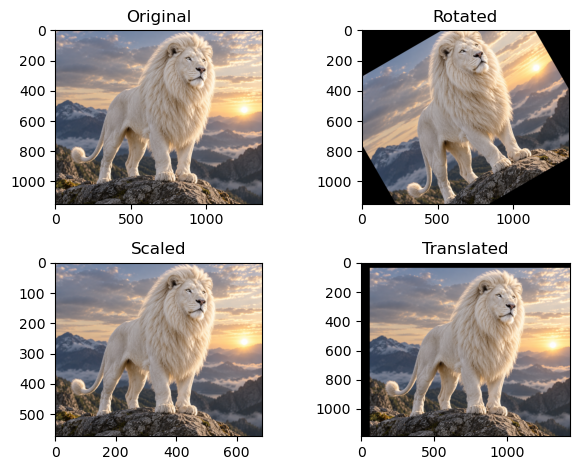

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image and convert BGR image to RGB
img = cv2.cvtColor(
    cv2.imread(r"C:\Users\GAGAN RAO K\Downloads\9dc590a4-d9fe-485a-bccc-dfd00767f7ec.png"),
    cv2.COLOR_BGR2RGB
)

# Get image height and width
h, w = img.shape[:2]


# Create rotation matrix
pok = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0)

# Rotate image by 30 degrees
rot = cv2.warpAffine(img, pok, (w, h))


# Scale image to 50% of original size
scale = cv2.resize(img, None, fx=0.5, fy=0.5)


# Create translation matrix
pok_trans = np.float32([
    [1, 0, 60],
    [0, 1, 40]
])

# Move image 60 pixels right and 40 pixels down
trans = cv2.warpAffine(img, pok_trans, (w + 60, h + 40))


# Titles for the output images
titles = ['Original', 'Rotated', 'Scaled', 'Translated']

# Store all images
imgs = [img, rot, scale, trans]


# Display all images
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 2, i)  # Create 2 rows and 2 columns
    plt.imshow(im)        # Display image
    plt.title(t)          # Display title
    plt.axis('on')       # Hide axis

# Arrange images neatly
plt.tight_layout()

# Show final output
plt.show()